<a href="https://www.kaggle.com/code/tanimationtv/starter-notebook-for-name-that-llm-competition?scriptVersionId=367007882" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Name That LLM: Starter Baseline (TF-IDF + Logistic Regression)


In [1]:
import pathlib

import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import FeatureUnion, Pipeline

CANDIDATES = [
    pathlib.Path('/kaggle/input/competitions/name-that-llm'),
    pathlib.Path('/kaggle/input/name-that-llm'),
]
DATA_DIR = next(p for p in CANDIDATES if (p / 'train.csv').exists())

train_df = pd.read_csv(DATA_DIR / 'train.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')

print(f'Train shape: {train_df.shape} | Unique models: {train_df["model"].nunique()} | Prompts: {train_df["prompt_id"].nunique()}')
print(f'Test shape: {test_df.shape}')
train_df.head(3)

Train shape: (2699, 4) | Unique models: 18 | Prompts: 150
Test shape: (3, 2)


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash


In [2]:
# Build Word + Character N-Gram TF-IDF + Logistic Regression Pipeline
model_pipeline = Pipeline(
    [
        (
            'features',
            FeatureUnion(
                [
                    (
                        'word_tfidf',
                        TfidfVectorizer(
                            ngram_range=(1, 2),
                            max_features=25000,
                            sublinear_tf=True,
                        ),
                    ),
                    (
                        'char_tfidf',
                        TfidfVectorizer(
                            analyzer='char',
                            ngram_range=(3, 5),
                            max_features=35000,
                            sublinear_tf=True,
                        ),
                    ),
                ]
            ),
        ),
        ('clf', LogisticRegression(C=2.0, max_iter=1000)),
    ]
)

# 5-fold CV that keeps each prompt in a single fold (test prompts are unseen), scored like the leaderboard
cv_scores = cross_val_score(
    model_pipeline,
    train_df['text'].fillna(''),
    train_df['model'],
    groups=train_df['prompt_id'],
    cv=GroupKFold(n_splits=5),
    scoring='balanced_accuracy',
    n_jobs=-1,
)
print(f'5-Fold Grouped CV Balanced Accuracy: {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}')

# Fit on full training set
model_pipeline.fit(train_df['text'].fillna(''), train_df['model'])

5-Fold Grouped CV Balanced Accuracy: 0.3167 +/- 0.0123


Pipeline(steps=[('features',
                 FeatureUnion(transformer_list=[('word_tfidf',
                                                 TfidfVectorizer(max_features=25000,
                                                                 ngram_range=(1,
                                                                              2),
                                                                 sublinear_tf=True)),
                                                ('char_tfidf',
                                                 TfidfVectorizer(analyzer='char',
                                                                 max_features=35000,
                                                                 ngram_range=(3,
                                                                              5),
                                                                 sublinear_tf=True))])),
                ('clf', LogisticRegression(C=2.0, max_iter=1000))])

In [3]:
# Batch inference on test.csv (1 example row interactively; the full hidden test set during the Leaderboard Rerun)
test_preds = model_pipeline.predict(test_df['text'].fillna(''))

submission = pd.DataFrame(
    {
        'id': test_df['id'],
        'model': test_preds,
    }
)

submission.to_parquet('submission.parquet', index=False)
print(f'Saved submission.parquet with {len(submission)} rows.')
submission.head(10)

Saved submission.parquet with 3 rows.


,id,model
0,00353fb1c541,gemini-3.6-flash
1,005f5a9a6139,gpt-5.6-terra
2,0062a53d5487,gemini-3.7-flash


In [4]:
import glob, os, re, time, warnings, pathlib
import numpy as np, pandas as pd
from scipy.sparse import hstack, vstack
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.multiclass import OneVsRestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import RobustScaler
from sklearn.svm import LinearSVC
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModel, AutoTokenizer

warnings.filterwarnings("ignore")
T0 = time.time()
def log(*a): print(f"[{time.time() - T0:7.1f}s]", *a, flush=True)
def ba(t, s): return balanced_accuracy_score(t, np.asarray(s).argmax(1))

# ============================================================================
# 1. DATA & SPLIT
# ============================================================================
def find_data_dir():
    for pat in ("/kaggle/input/**/train.csv", "/kaggle/input/*/train.csv"):
        for h in sorted({os.path.dirname(p) for p in glob.glob(pat, recursive=True)}):
            if os.path.exists(os.path.join(h, "test.csv")):
                return pathlib.Path(h)
    raise FileNotFoundError("train.csv not found")

DATA_DIR = find_data_dir()
train_full = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
for df in (train_full, test_df): df["text"] = df["text"].fillna("").astype(str)

CLASSES = np.array(sorted(train_full["model"].unique()))
NC = len(CLASSES)

# External Data
MIN_W, MAX_W, MIN_CHARS = 35, 280, 200
def clean_external(df):
    df = df[["text", "model"]].dropna(subset=["model"])
    df = df[df["model"].isin(CLASSES)].copy()
    df["text"] = df["text"].fillna("").astype(str)
    nw = df["text"].str.split().str.len()
    return df[nw.between(MIN_W, MAX_W) & (df["text"].str.len() > MIN_CHARS)]

def load_external():
    out = []
    for p in glob.glob("/kaggle/input/**/passages.csv", recursive=True):
        if "/name-that-llm/" in p: continue
        try:
            d = pd.read_csv(p)
            if "passes_funnel" in d.columns: d = d[d["passes_funnel"].astype(bool)]
            if "is_refusal" in d.columns: d = d[~d["is_refusal"].astype(bool)]
            if {"text", "model"} <= set(d.columns): out.append(clean_external(d))
        except: pass
    return pd.concat(out, ignore_index=True).drop_duplicates(subset=["text"]) if out else pd.DataFrame(columns=["text", "model"])

EXT = load_external()
if len(EXT):
    E_X = EXT["text"].values
    E_Y = np.searchsorted(CLASSES, EXT["model"].values)
    log(f"✅ External data: {len(E_X)} rows")
else:
    E_X, E_Y = np.array([]), np.array([])

gss = GroupShuffleSplit(n_splits=1, train_size=0.7, random_state=42)
tr_idx, va_idx = next(gss.split(train_full, groups=train_full["prompt_id"]))
train_df = train_full.iloc[tr_idx].reset_index(drop=True)
val_df = train_full.iloc[va_idx].reset_index(drop=True)

y_train = np.searchsorted(CLASSES, train_df["model"].values)
y_val = np.searchsorted(CLASSES, val_df["model"].values)
X_train, X_val = train_df["text"].values, val_df["text"].values
XT = test_df["text"].values

# ============================================================================
# 2. MULTI-DEPTH EMBEDDINGS
# ============================================================================
def find_model():
    cfgs = glob.glob("/kaggle/input/**/config.json", recursive=True)
    cands = [os.path.dirname(c) for c in cfgs if "deberta" in c.lower() and "small" not in c.lower()]
    return cands[0] if cands else None

MODEL_PATH = find_model()
LLM_E_train = LLM_E_val = LLM_E_test = LLM_E_ext = None

if MODEL_PATH:
    log(f"Extracting multi-depth embeddings from {MODEL_PATH}...")
    tok = AutoTokenizer.from_pretrained(MODEL_PATH, use_fast=True)
    model = AutoModel.from_pretrained(MODEL_PATH).eval()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    if device == "cuda": model = model.half()
    
    LAYERS = [12, 18, 24] 

    @torch.inference_mode()
    def embed(texts, batch=16, max_len=384):
        chunks = []
        for i in range(0, len(texts), batch):
            enc = tok(list(texts[i:i + batch]), truncation=True, max_length=max_len, padding=True, return_tensors="pt").to(device)
            if device == "cuda":
                enc = {k: (v.half() if v.dtype == torch.float32 else v) for k, v in enc.items()}
            hs = model(**enc, output_hidden_states=True).hidden_states
            mf = enc["attention_mask"].unsqueeze(-1).float()
            chunks.append(np.hstack([((hs[L].float() * mf).sum(1) / mf.sum(1).clamp(min=1)).cpu().numpy() for L in LAYERS]))
        return np.vstack(chunks).astype(np.float32)

    LLM_E_train = embed(X_train)
    LLM_E_val = embed(X_val)
    LLM_E_test = embed(XT)
    LLM_E_ext = embed(E_X) if len(E_X) else None
    log(f"✓ Embeddings: {LLM_E_train.shape}")
    del model; torch.cuda.empty_cache()

# ============================================================================
# 3. TRAIN A CUSTOM NEURAL HEAD ON EMBEDDINGS
# ============================================================================
class LLMHead(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )
    def forward(self, x): return self.net(x)

class EmbeddingDataset(Dataset):
    def __init__(self, embeddings, labels):
        self.embeddings = torch.tensor(embeddings, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)
    def __len__(self): return len(self.labels)
    def __getitem__(self, idx): return self.embeddings[idx], self.labels[idx]

if LLM_E_train is not None:
    log("Training custom neural head on embeddings...")
    sc_llm = RobustScaler().fit(LLM_E_train)
    Z_tr = sc_llm.transform(LLM_E_train)
    Z_va = sc_llm.transform(LLM_E_val)
    Z_te = sc_llm.transform(LLM_E_test)
    
    if LLM_E_ext is not None:
        Z_tr = np.vstack([Z_tr, sc_llm.transform(LLM_E_ext)])
        fit_y_emb = np.concatenate([y_train, E_Y])
    else:
        fit_y_emb = y_train

    train_dataset = EmbeddingDataset(Z_tr, fit_y_emb)
    val_dataset = EmbeddingDataset(Z_va, y_val)
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

    head = LLMHead(Z_tr.shape[1], NC).to("cuda")
    optimizer = optim.Adam(head.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(10):
        head.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to("cuda"), y_batch.to("cuda")
            optimizer.zero_grad()
            outputs = head(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
        log(f"  Epoch {epoch+1}/10 Loss: {loss.item():.4f}")

    head.eval()
    val_preds = []
    with torch.no_grad():
        for X_batch, _ in val_loader:
            X_batch = X_batch.to("cuda")
            outputs = head(X_batch)
            val_preds.extend(torch.softmax(outputs, dim=1).cpu().numpy())
    
    val_probs = np.array(val_preds)
    log(f"  Neural Head Val: {ba(y_val, val_probs):.4f}")

    test_dataset = EmbeddingDataset(Z_te, np.zeros(len(Z_te)))
    test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
    test_preds = []
    with torch.no_grad():
        for X_batch, _ in test_loader:
            X_batch = X_batch.to("cuda")
            outputs = head(X_batch)
            test_preds.extend(torch.softmax(outputs, dim=1).cpu().numpy())
    test_probs = np.array(test_preds)
else:
    log("No embeddings found. Skipping neural head.")

# ============================================================================
# 4. SUBMIT
# ============================================================================
pred = CLASSES[test_probs.argmax(1)]
sub = pd.DataFrame({"id": test_df["id"].values, "model": pred})
sub.to_csv("submission.csv", index=False)
sub.to_parquet("submission.parquet", index=False)
log("✓ Saved submission.parquet")

[    1.2s] ✅ External data: 12003 rows
[    1.3s] Extracting multi-depth embeddings from /kaggle/input/datasets/prvsiyan/deberta-v3-large-weights/deberta-v3-large...


[transformers] The tokenizer you are loading from '/kaggle/input/datasets/prvsiyan/deberta-v3-large-weights/deberta-v3-large' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: /kaggle/input/datasets/prvsiyan/deberta-v3-large-weights/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identi

[  322.0s] ✓ Embeddings: (1889, 3072)
[  322.0s] Training custom neural head on embeddings...
[  324.1s]   Epoch 1/10 Loss: 1.4797
[  325.0s]   Epoch 2/10 Loss: 1.6773
[  325.9s]   Epoch 3/10 Loss: 1.2477
[  326.7s]   Epoch 4/10 Loss: 0.9661
[  327.6s]   Epoch 5/10 Loss: 0.7106
[  328.4s]   Epoch 6/10 Loss: 1.1382
[  329.2s]   Epoch 7/10 Loss: 1.1445
[  330.1s]   Epoch 8/10 Loss: 1.1890
[  330.9s]   Epoch 9/10 Loss: 1.1487
[  331.7s]   Epoch 10/10 Loss: 0.8313
[  331.7s]   Neural Head Val: 0.4272
[  331.7s] ✓ Saved submission.parquet


In [5]:
import glob, os, re, time, warnings, pathlib
import numpy as np, pandas as pd
from scipy.sparse import hstack, vstack
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import RobustScaler
from sklearn.svm import LinearSVC
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModel, AutoTokenizer

warnings.filterwarnings("ignore")
T0 = time.time()
def log(*a): print(f"[{time.time() - T0:7.1f}s]", *a, flush=True)
def ba(t, s): return balanced_accuracy_score(t, np.asarray(s).argmax(1))

# ============================================================================
# 1. DATA & SPLIT
# ============================================================================
def find_data_dir():
    for pat in ("/kaggle/input/**/train.csv", "/kaggle/input/*/train.csv"):
        for h in sorted({os.path.dirname(p) for p in glob.glob(pat, recursive=True)}):
            if os.path.exists(os.path.join(h, "test.csv")):
                return pathlib.Path(h)
    raise FileNotFoundError("train.csv not found")

DATA_DIR = find_data_dir()
train_full = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
for df in (train_full, test_df): df["text"] = df["text"].fillna("").astype(str)

CLASSES = np.array(sorted(train_full["model"].unique()))
NC = len(CLASSES)

# External Data
MIN_W, MAX_W, MIN_CHARS = 35, 280, 200
def clean_external(df):
    df = df[["text", "model"]].dropna(subset=["model"])
    df = df[df["model"].isin(CLASSES)].copy()
    df["text"] = df["text"].fillna("").astype(str)
    nw = df["text"].str.split().str.len()
    return df[nw.between(MIN_W, MAX_W) & (df["text"].str.len() > MIN_CHARS)]

def load_external():
    out = []
    for p in glob.glob("/kaggle/input/**/passages.csv", recursive=True):
        if "/name-that-llm/" in p: continue
        try:
            d = pd.read_csv(p)
            if "passes_funnel" in d.columns: d = d[d["passes_funnel"].astype(bool)]
            if "is_refusal" in d.columns: d = d[~d["is_refusal"].astype(bool)]
            if {"text", "model"} <= set(d.columns): out.append(clean_external(d))
        except: pass
    return pd.concat(out, ignore_index=True).drop_duplicates(subset=["text"]) if out else pd.DataFrame(columns=["text", "model"])

EXT = load_external()
if len(EXT):
    E_X = EXT["text"].values
    E_Y = np.searchsorted(CLASSES, EXT["model"].values)
    log(f"✅ External data: {len(E_X)} rows")
else:
    E_X, E_Y = np.array([]), np.array([])

gss = GroupShuffleSplit(n_splits=1, train_size=0.7, random_state=42)
tr_idx, va_idx = next(gss.split(train_full, groups=train_full["prompt_id"]))
train_df = train_full.iloc[tr_idx].reset_index(drop=True)
val_df = train_full.iloc[va_idx].reset_index(drop=True)

y_train = np.searchsorted(CLASSES, train_df["model"].values)
y_val = np.searchsorted(CLASSES, val_df["model"].values)
X_train, X_val = train_df["text"].values, val_df["text"].values
XT = test_df["text"].values

# ============================================================================
# 2. MULTI-DEPTH EMBEDDINGS
# ============================================================================
def find_model():
    cfgs = glob.glob("/kaggle/input/**/config.json", recursive=True)
    cands = [os.path.dirname(c) for c in cfgs if "deberta" in c.lower() and "small" not in c.lower()]
    return cands[0] if cands else None

MODEL_PATH = find_model()
LLM_E_train = LLM_E_val = LLM_E_test = LLM_E_ext = None

if MODEL_PATH:
    log(f"Extracting multi-depth embeddings from {MODEL_PATH}...")
    tok = AutoTokenizer.from_pretrained(MODEL_PATH, use_fast=True)
    model = AutoModel.from_pretrained(MODEL_PATH).eval()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    if device == "cuda": model = model.half()
    
    LAYERS = [12, 18, 24] 

    @torch.inference_mode()
    def embed(texts, batch=16, max_len=384):
        chunks = []
        for i in range(0, len(texts), batch):
            enc = tok(list(texts[i:i + batch]), truncation=True, max_length=max_len, padding=True, return_tensors="pt").to(device)
            if device == "cuda":
                enc = {k: (v.half() if v.dtype == torch.float32 else v) for k, v in enc.items()}
            hs = model(**enc, output_hidden_states=True).hidden_states
            mf = enc["attention_mask"].unsqueeze(-1).float()
            chunks.append(np.hstack([((hs[L].float() * mf).sum(1) / mf.sum(1).clamp(min=1)).cpu().numpy() for L in LAYERS]))
        return np.vstack(chunks).astype(np.float32)

    LLM_E_train = embed(X_train)
    LLM_E_val = embed(X_val)
    LLM_E_test = embed(XT)
    LLM_E_ext = embed(E_X) if len(E_X) else None
    log(f"✓ Embeddings: {LLM_E_train.shape}")
    del model; torch.cuda.empty_cache()

# ============================================================================
# 3. TRAIN NEURAL HEAD
# ============================================================================
class LLMHead(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )
    def forward(self, x): return self.net(x)

class EmbeddingDataset(Dataset):
    def __init__(self, embeddings, labels):
        self.embeddings = torch.tensor(embeddings, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)
    def __len__(self): return len(self.labels)
    def __getitem__(self, idx): return self.embeddings[idx], self.labels[idx]

if LLM_E_train is not None:
    log("Training custom neural head on embeddings...")
    sc_llm = RobustScaler().fit(LLM_E_train)
    Z_tr = sc_llm.transform(LLM_E_train)
    Z_va = sc_llm.transform(LLM_E_val)
    Z_te = sc_llm.transform(LLM_E_test)
    
    if LLM_E_ext is not None:
        Z_tr = np.vstack([Z_tr, sc_llm.transform(LLM_E_ext)])
        fit_y_emb = np.concatenate([y_train, E_Y])
    else:
        fit_y_emb = y_train

    train_dataset = EmbeddingDataset(Z_tr, fit_y_emb)
    val_dataset = EmbeddingDataset(Z_va, y_val)
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

    head = LLMHead(Z_tr.shape[1], NC).to("cuda")
    optimizer = optim.Adam(head.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(5): # Reduced epochs for speed
        head.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to("cuda"), y_batch.to("cuda")
            optimizer.zero_grad()
            outputs = head(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()

    head.eval()
    val_preds = []
    with torch.no_grad():
        for X_batch, _ in val_loader:
            X_batch = X_batch.to("cuda")
            outputs = head(X_batch)
            val_preds.extend(torch.softmax(outputs, dim=1).cpu().numpy())
    val_probs = np.array(val_preds)
    log(f"  Neural Head Val: {ba(y_val, val_probs):.4f}")

    test_dataset = EmbeddingDataset(Z_te, np.zeros(len(Z_te)))
    test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
    test_preds = []
    with torch.no_grad():
        for X_batch, _ in test_loader:
            X_batch = X_batch.to("cuda")
            outputs = head(X_batch)
            test_preds.extend(torch.softmax(outputs, dim=1).cpu().numpy())
    test_probs = np.array(test_preds)

# ============================================================================
# 4. BLEND NEURAL HEAD WITH CLASSIC MODELS
# ============================================================================
log("Training classic models...")
def style_feats(texts):
    rows = []
    for t in texts:
        nw, nc = max(len(t.split()), 1), max(len(t), 1)
        alpha = max(sum(c.isalpha() for c in t), 1)
        rows.append([
            np.log1p(nc), np.log1p(nw), nc / nw,
            (t.count("\u2014") + t.count("\u2013")) / nc * 1000,
            t.count(";") / nc * 1000, t.count(",") / nc * 1000,
            len(re.findall(r"\*\*.+?\*\*", t)), len(re.findall(r"^\s*[\*\-\u2022]\s+", t, re.M)),
            sum(c.isupper() for c in t) / alpha, len(re.findall(r"[\u200B-\u200D\uFEFF]", t))
        ])
    return np.nan_to_num(np.array(rows, dtype=np.float64))

S_train = style_feats(X_train)
S_val = style_feats(X_val)
S_test = style_feats(XT)
S_ext = style_feats(E_X) if len(E_X) else np.zeros((0, S_train.shape[1]))

sc_style = RobustScaler().fit(S_train)
S_train_sc = sc_style.transform(S_train)
S_val_sc = sc_style.transform(S_val)
S_test_sc = sc_style.transform(S_test)
S_ext_sc = sc_style.transform(S_ext)

c_vec = TfidfVectorizer(analyzer="char", ngram_range=(1, 5), lowercase=False, sublinear_tf=True, min_df=2, max_features=200000)
w_vec = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), lowercase=False, sublinear_tf=True, min_df=2, max_features=100000)

fit_text = np.concatenate([X_train, E_X]) if len(E_X) else X_train
fit_y = np.concatenate([y_train, E_Y]) if len(E_X) else y_train

A_fit = hstack([c_vec.fit_transform(fit_text), w_vec.fit_transform(fit_text)]).tocsr()
A_val = hstack([c_vec.transform(X_val), w_vec.transform(X_val)]).tocsr()
A_test = hstack([c_vec.transform(XT), w_vec.transform(XT)]).tocsr()

def align(A, cls):
    A = np.asarray(A)
    if A.shape[1] == NC: return A
    out = np.full((A.shape[0], NC), A.min() - 1.0)
    out[:, cls] = A
    return out

OOF, TEST = {}, {}

# SVM
svm = LinearSVC(C=0.5, class_weight="balanced", dual=False, max_iter=5000).fit(A_fit, fit_y)
OOF["svm"] = align(svm.decision_function(A_val), svm.classes_)
TEST["svm"] = align(svm.decision_function(A_test), svm.classes_)
log(f"  SVM Val: {ba(y_val, OOF['svm']):.4f}")

# Ridge
ridge = OneVsRestClassifier(RidgeClassifier(alpha=1.0, class_weight="balanced")).fit(A_fit, fit_y)
OOF["ridge"] = align(ridge.decision_function(A_val), ridge.classes_)
TEST["ridge"] = align(ridge.decision_function(A_test), ridge.classes_)
log(f"  Ridge Val: {ba(y_val, OOF['ridge']):.4f}")

# ExtraTrees
svd = TruncatedSVD(n_components=100, random_state=42)
Z_fit = svd.fit_transform(A_fit)
Z_val = svd.transform(A_val)
Z_test = svd.transform(A_test)
X_tree_fit = np.hstack([Z_fit, np.vstack([S_train_sc, S_ext_sc]) if len(E_X) else S_train_sc])
X_tree_val = np.hstack([Z_val, S_val_sc])
X_tree_test = np.hstack([Z_test, S_test_sc])
et = ExtraTreesClassifier(n_estimators=300, max_depth=12, class_weight="balanced", random_state=42, n_jobs=-1).fit(X_tree_fit, fit_y)
OOF["et"] = align(np.log(et.predict_proba(X_tree_val) + 1e-9), et.classes_)
TEST["et"] = align(np.log(et.predict_proba(X_tree_test) + 1e-9), et.classes_)
log(f"  ExtraTrees Val: {ba(y_val, OOF['et']):.4f}")

# Add Neural Head to blend
OOF["neural"] = np.log(val_probs + 1e-9)
TEST["neural"] = np.log(test_probs + 1e-9)
log(f"  Neural Head Val: {ba(y_val, OOF['neural']):.4f}")

# ============================================================================
# 5. BLEND & SUBMIT
# ============================================================================
def rownorm(s):
    s = np.asarray(s, dtype=np.float64)
    return (s - s.mean(1, keepdims=True)) / (s.std(1, keepdims=True) + 1e-9)

names = list(OOF.keys())
pred_val = sum(rownorm(OOF[k]) for k in names) / len(names)
log(f"🏆 V47 Final Blend Val: {ba(y_val, pred_val):.4f}")

pred_test = sum(rownorm(TEST[k]) for k in names) / len(names)
pred = CLASSES[pred_test.argmax(1)]

sub = pd.DataFrame({"id": test_df["id"].values, "model": pred})
sub.to_csv("submission.csv", index=False)
sub.to_parquet("submission.parquet", index=False)
log("✓ Saved submission.parquet")

[    0.5s] ✅ External data: 12003 rows
[    0.6s] Extracting multi-depth embeddings from /kaggle/input/datasets/prvsiyan/deberta-v3-large-weights/deberta-v3-large...


[transformers] The tokenizer you are loading from '/kaggle/input/datasets/prvsiyan/deberta-v3-large-weights/deberta-v3-large' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: /kaggle/input/datasets/prvsiyan/deberta-v3-large-weights/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identi

[  294.8s] ✓ Embeddings: (1889, 3072)
[  294.8s] Training custom neural head on embeddings...
[  300.1s]   Neural Head Val: 0.4321
[  300.1s] Training classic models...
[  483.0s]   SVM Val: 0.3852
[  615.4s]   Ridge Val: 0.3667
[  671.6s]   ExtraTrees Val: 0.2259
[  671.6s]   Neural Head Val: 0.4321
[  671.6s] 🏆 V47 Final Blend Val: 0.4358
[  671.6s] ✓ Saved submission.parquet


In [6]:
import glob, os, re, time, warnings, pathlib
import numpy as np, pandas as pd
from scipy.sparse import hstack, vstack
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.multiclass import OneVsRestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import RobustScaler
from sklearn.svm import LinearSVC
import torch
from transformers import AutoModel, AutoTokenizer

warnings.filterwarnings("ignore")
T0 = time.time()
def log(*a): print(f"[{time.time() - T0:7.1f}s]", *a, flush=True)
def ba(t, s): return balanced_accuracy_score(t, np.asarray(s).argmax(1))

# ============================================================================
# 1. DATA & SPLIT
# ============================================================================
def find_data_dir():
    for pat in ("/kaggle/input/**/train.csv", "/kaggle/input/*/train.csv"):
        for h in sorted({os.path.dirname(p) for p in glob.glob(pat, recursive=True)}):
            if os.path.exists(os.path.join(h, "test.csv")):
                return pathlib.Path(h)
    raise FileNotFoundError("train.csv not found")

DATA_DIR = find_data_dir()
train_full = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
for df in (train_full, test_df): df["text"] = df["text"].fillna("").astype(str)

CLASSES = np.array(sorted(train_full["model"].unique()))
NC = len(CLASSES)

# External Data
MIN_W, MAX_W, MIN_CHARS = 35, 280, 200
def clean_external(df):
    df = df[["text", "model"]].dropna(subset=["model"])
    df = df[df["model"].isin(CLASSES)].copy()
    df["text"] = df["text"].fillna("").astype(str)
    nw = df["text"].str.split().str.len()
    return df[nw.between(MIN_W, MAX_W) & (df["text"].str.len() > MIN_CHARS)]

def load_external():
    out = []
    for p in glob.glob("/kaggle/input/**/passages.csv", recursive=True):
        if "/name-that-llm/" in p: continue
        try:
            d = pd.read_csv(p)
            if "passes_funnel" in d.columns: d = d[d["passes_funnel"].astype(bool)]
            if "is_refusal" in d.columns: d = d[~d["is_refusal"].astype(bool)]
            if {"text", "model"} <= set(d.columns): out.append(clean_external(d))
        except: pass
    return pd.concat(out, ignore_index=True).drop_duplicates(subset=["text"]) if out else pd.DataFrame(columns=["text", "model"])

EXT = load_external()
if len(EXT):
    E_X = EXT["text"].values
    E_Y = np.searchsorted(CLASSES, EXT["model"].values)
    log(f"✅ External data: {len(E_X)} rows")
else:
    E_X, E_Y = np.array([]), np.array([])

gss = GroupShuffleSplit(n_splits=1, train_size=0.7, random_state=42)
tr_idx, va_idx = next(gss.split(train_full, groups=train_full["prompt_id"]))
train_df = train_full.iloc[tr_idx].reset_index(drop=True)
val_df = train_full.iloc[va_idx].reset_index(drop=True)

y_train = np.searchsorted(CLASSES, train_df["model"].values)
y_val = np.searchsorted(CLASSES, val_df["model"].values)
X_train, X_val = train_df["text"].values, val_df["text"].values
XT = test_df["text"].values

# ============================================================================
# 2. MULTI-DEPTH EMBEDDINGS
# ============================================================================
def find_model():
    cfgs = glob.glob("/kaggle/input/**/config.json", recursive=True)
    cands = [os.path.dirname(c) for c in cfgs if "deberta" in c.lower() and "small" not in c.lower()]
    return cands[0] if cands else None

MODEL_PATH = find_model()
LLM_E_train = LLM_E_val = LLM_E_test = LLM_E_ext = None

if MODEL_PATH:
    log(f"Extracting multi-depth embeddings from {MODEL_PATH}...")
    tok = AutoTokenizer.from_pretrained(MODEL_PATH, use_fast=True)
    model = AutoModel.from_pretrained(MODEL_PATH).eval()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    if device == "cuda": model = model.half()
    
    LAYERS = [12, 18, 24] 

    @torch.inference_mode()
    def embed(texts, batch=16, max_len=384):
        chunks = []
        for i in range(0, len(texts), batch):
            enc = tok(list(texts[i:i + batch]), truncation=True, max_length=max_len, padding=True, return_tensors="pt").to(device)
            if device == "cuda":
                enc = {k: (v.half() if v.dtype == torch.float32 else v) for k, v in enc.items()}
            hs = model(**enc, output_hidden_states=True).hidden_states
            mf = enc["attention_mask"].unsqueeze(-1).float()
            chunks.append(np.hstack([((hs[L].float() * mf).sum(1) / mf.sum(1).clamp(min=1)).cpu().numpy() for L in LAYERS]))
        return np.vstack(chunks).astype(np.float32)

    LLM_E_train = embed(X_train)
    LLM_E_val = embed(X_val)
    LLM_E_test = embed(XT)
    LLM_E_ext = embed(E_X) if len(E_X) else None
    log(f"✓ Embeddings: {LLM_E_train.shape}")
    del model; torch.cuda.empty_cache()

# ============================================================================
# 3. FEATURES & MODELS
# ============================================================================
def style_feats(texts):
    rows = []
    for t in texts:
        nw, nc = max(len(t.split()), 1), max(len(t), 1)
        alpha = max(sum(c.isalpha() for c in t), 1)
        rows.append([
            np.log1p(nc), np.log1p(nw), nc / nw,
            (t.count("\u2014") + t.count("\u2013")) / nc * 1000,
            t.count(";") / nc * 1000, t.count(",") / nc * 1000,
            len(re.findall(r"\*\*.+?\*\*", t)), len(re.findall(r"^\s*[\*\-\u2022]\s+", t, re.M)),
            sum(c.isupper() for c in t) / alpha, len(re.findall(r"[\u200B-\u200D\uFEFF]", t))
        ])
    return np.nan_to_num(np.array(rows, dtype=np.float64))

S_train = style_feats(X_train)
S_val = style_feats(X_val)
S_test = style_feats(XT)
S_ext = style_feats(E_X) if len(E_X) else np.zeros((0, S_train.shape[1]))

sc_style = RobustScaler().fit(S_train)
S_train_sc = sc_style.transform(S_train)
S_val_sc = sc_style.transform(S_val)
S_test_sc = sc_style.transform(S_test)
S_ext_sc = sc_style.transform(S_ext)

c_vec = TfidfVectorizer(analyzer="char", ngram_range=(1, 5), lowercase=False, sublinear_tf=True, min_df=2, max_features=200000)
w_vec = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), lowercase=False, sublinear_tf=True, min_df=2, max_features=100000)

fit_text = np.concatenate([X_train, E_X]) if len(E_X) else X_train
fit_y = np.concatenate([y_train, E_Y]) if len(E_X) else y_train

A_fit = hstack([c_vec.fit_transform(fit_text), w_vec.fit_transform(fit_text)]).tocsr()
A_val = hstack([c_vec.transform(X_val), w_vec.transform(X_val)]).tocsr()
A_test = hstack([c_vec.transform(XT), w_vec.transform(XT)]).tocsr()

OOF, TEST = {}, {}
log("Training Base Models...")
def align(A, cls):
    A = np.asarray(A)
    if A.shape[1] == NC: return A
    out = np.full((A.shape[0], NC), A.min() - 1.0)
    out[:, cls] = A
    return out

# 1. SVM
svm = LinearSVC(C=0.5, class_weight="balanced", dual=False, max_iter=5000).fit(A_fit, fit_y)
OOF["svm"] = align(svm.decision_function(A_val), svm.classes_)
TEST["svm"] = align(svm.decision_function(A_test), svm.classes_)
log(f"  SVM Val: {ba(y_val, OOF['svm']):.4f}")

# 2. Ridge
ridge = OneVsRestClassifier(RidgeClassifier(alpha=1.0, class_weight="balanced")).fit(A_fit, fit_y)
OOF["ridge"] = align(ridge.decision_function(A_val), ridge.classes_)
TEST["ridge"] = align(ridge.decision_function(A_test), ridge.classes_)
log(f"  Ridge Val: {ba(y_val, OOF['ridge']):.4f}")

# 3. ExtraTrees
svd = TruncatedSVD(n_components=100, random_state=42)
Z_fit = svd.fit_transform(A_fit)
Z_val = svd.transform(A_val)
Z_test = svd.transform(A_test)
X_tree_fit = np.hstack([Z_fit, np.vstack([S_train_sc, S_ext_sc]) if len(E_X) else S_train_sc])
X_tree_val = np.hstack([Z_val, S_val_sc])
X_tree_test = np.hstack([Z_test, S_test_sc])
et = ExtraTreesClassifier(n_estimators=300, max_depth=12, class_weight="balanced", random_state=42, n_jobs=-1).fit(X_tree_fit, fit_y)
OOF["et"] = align(np.log(et.predict_proba(X_tree_val) + 1e-9), et.classes_)
TEST["et"] = align(np.log(et.predict_proba(X_tree_test) + 1e-9), et.classes_)
log(f"  ExtraTrees Val: {ba(y_val, OOF['et']):.4f}")

# 4-5. DeBERTa Models
if LLM_E_train is not None:
    sc_llm = RobustScaler().fit(LLM_E_train)
    Z_tr = sc_llm.transform(LLM_E_train)
    Z_va = sc_llm.transform(LLM_E_val)
    Z_te = sc_llm.transform(LLM_E_test)
    if LLM_E_ext is not None:
        Z_tr = np.vstack([Z_tr, sc_llm.transform(LLM_E_ext)])
        fit_y_emb = np.concatenate([y_train, E_Y])
    else:
        fit_y_emb = y_train

    mlp = MLPClassifier(hidden_layer_sizes=(128, 64), alpha=0.01, max_iter=500, random_state=42, early_stopping=True).fit(Z_tr, fit_y_emb)
    OOF["mlp"] = align(np.log(mlp.predict_proba(Z_va) + 1e-9), np.arange(NC))
    TEST["mlp"] = align(np.log(mlp.predict_proba(Z_te) + 1e-9), np.arange(NC))
    log(f"  MLP Val: {ba(y_val, OOF['mlp']):.4f}")

    lr_emb = LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000).fit(Z_tr, fit_y_emb)
    OOF["lr_emb"] = align(lr_emb.decision_function(Z_va), lr_emb.classes_)
    TEST["lr_emb"] = align(lr_emb.decision_function(Z_te), lr_emb.classes_)
    log(f"  LR (Emb) Val: {ba(y_val, OOF['lr_emb']):.4f}")

# ============================================================================
# 4. BLEND & SUBMIT (The 0.4691 Configuration)
# ============================================================================
def rownorm(s):
    s = np.asarray(s, dtype=np.float64)
    return (s - s.mean(1, keepdims=True)) / (s.std(1, keepdims=True) + 1e-9)

names = list(OOF.keys())
pred_val = sum(rownorm(OOF[k]) for k in names) / len(names)
log(f"🏆 Equal-Weight Blend Val: {ba(y_val, pred_val):.4f}")

pred_test = sum(rownorm(TEST[k]) for k in names) / len(names)
pred = CLASSES[pred_test.argmax(1)]

sub = pd.DataFrame({"id": test_df["id"].values, "model": pred})
sub.to_csv("submission.csv", index=False)
sub.to_parquet("submission.parquet", index=False)
log("✓ Saved submission.parquet")

[    0.5s] ✅ External data: 12003 rows
[    0.5s] Extracting multi-depth embeddings from /kaggle/input/datasets/prvsiyan/deberta-v3-large-weights/deberta-v3-large...


[transformers] The tokenizer you are loading from '/kaggle/input/datasets/prvsiyan/deberta-v3-large-weights/deberta-v3-large' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: /kaggle/input/datasets/prvsiyan/deberta-v3-large-weights/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identi

[  295.1s] ✓ Embeddings: (1889, 3072)
[  327.6s] Training Base Models...
[  475.5s]   SVM Val: 0.3852
[  605.9s]   Ridge Val: 0.3667
[  661.8s]   ExtraTrees Val: 0.2259
[  672.9s]   MLP Val: 0.4469
[  731.7s]   LR (Emb) Val: 0.4284
[  731.7s] 🏆 Equal-Weight Blend Val: 0.4691
[  731.7s] ✓ Saved submission.parquet


[    0.5s] ✅ External data: 12003 rows
[    0.5s] Extracting multi-depth embeddings from /kaggle/input/datasets/prvsiyan/deberta-v3-large-weights/deberta-v3-large...


[transformers] The tokenizer you are loading from '/kaggle/input/datasets/prvsiyan/deberta-v3-large-weights/deberta-v3-large' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: /kaggle/input/datasets/prvsiyan/deberta-v3-large-weights/deberta-v3-large
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identi

[  295.3s] ✓ Embeddings: (1889, 3072)
[  327.3s] Training Base Models...
[  475.4s]   SVM Val: 0.3852
[  605.5s]   Ridge Val: 0.3667
[  661.3s]   ExtraTrees Val: 0.2259
[  672.4s]   MLP Val: 0.4469
[  732.3s]   LR (Emb) Val: 0.4284
[  732.3s] 🏆 Equal-Weight Blend Val: 0.4691
[  732.3s] Generating Confusion Matrix...


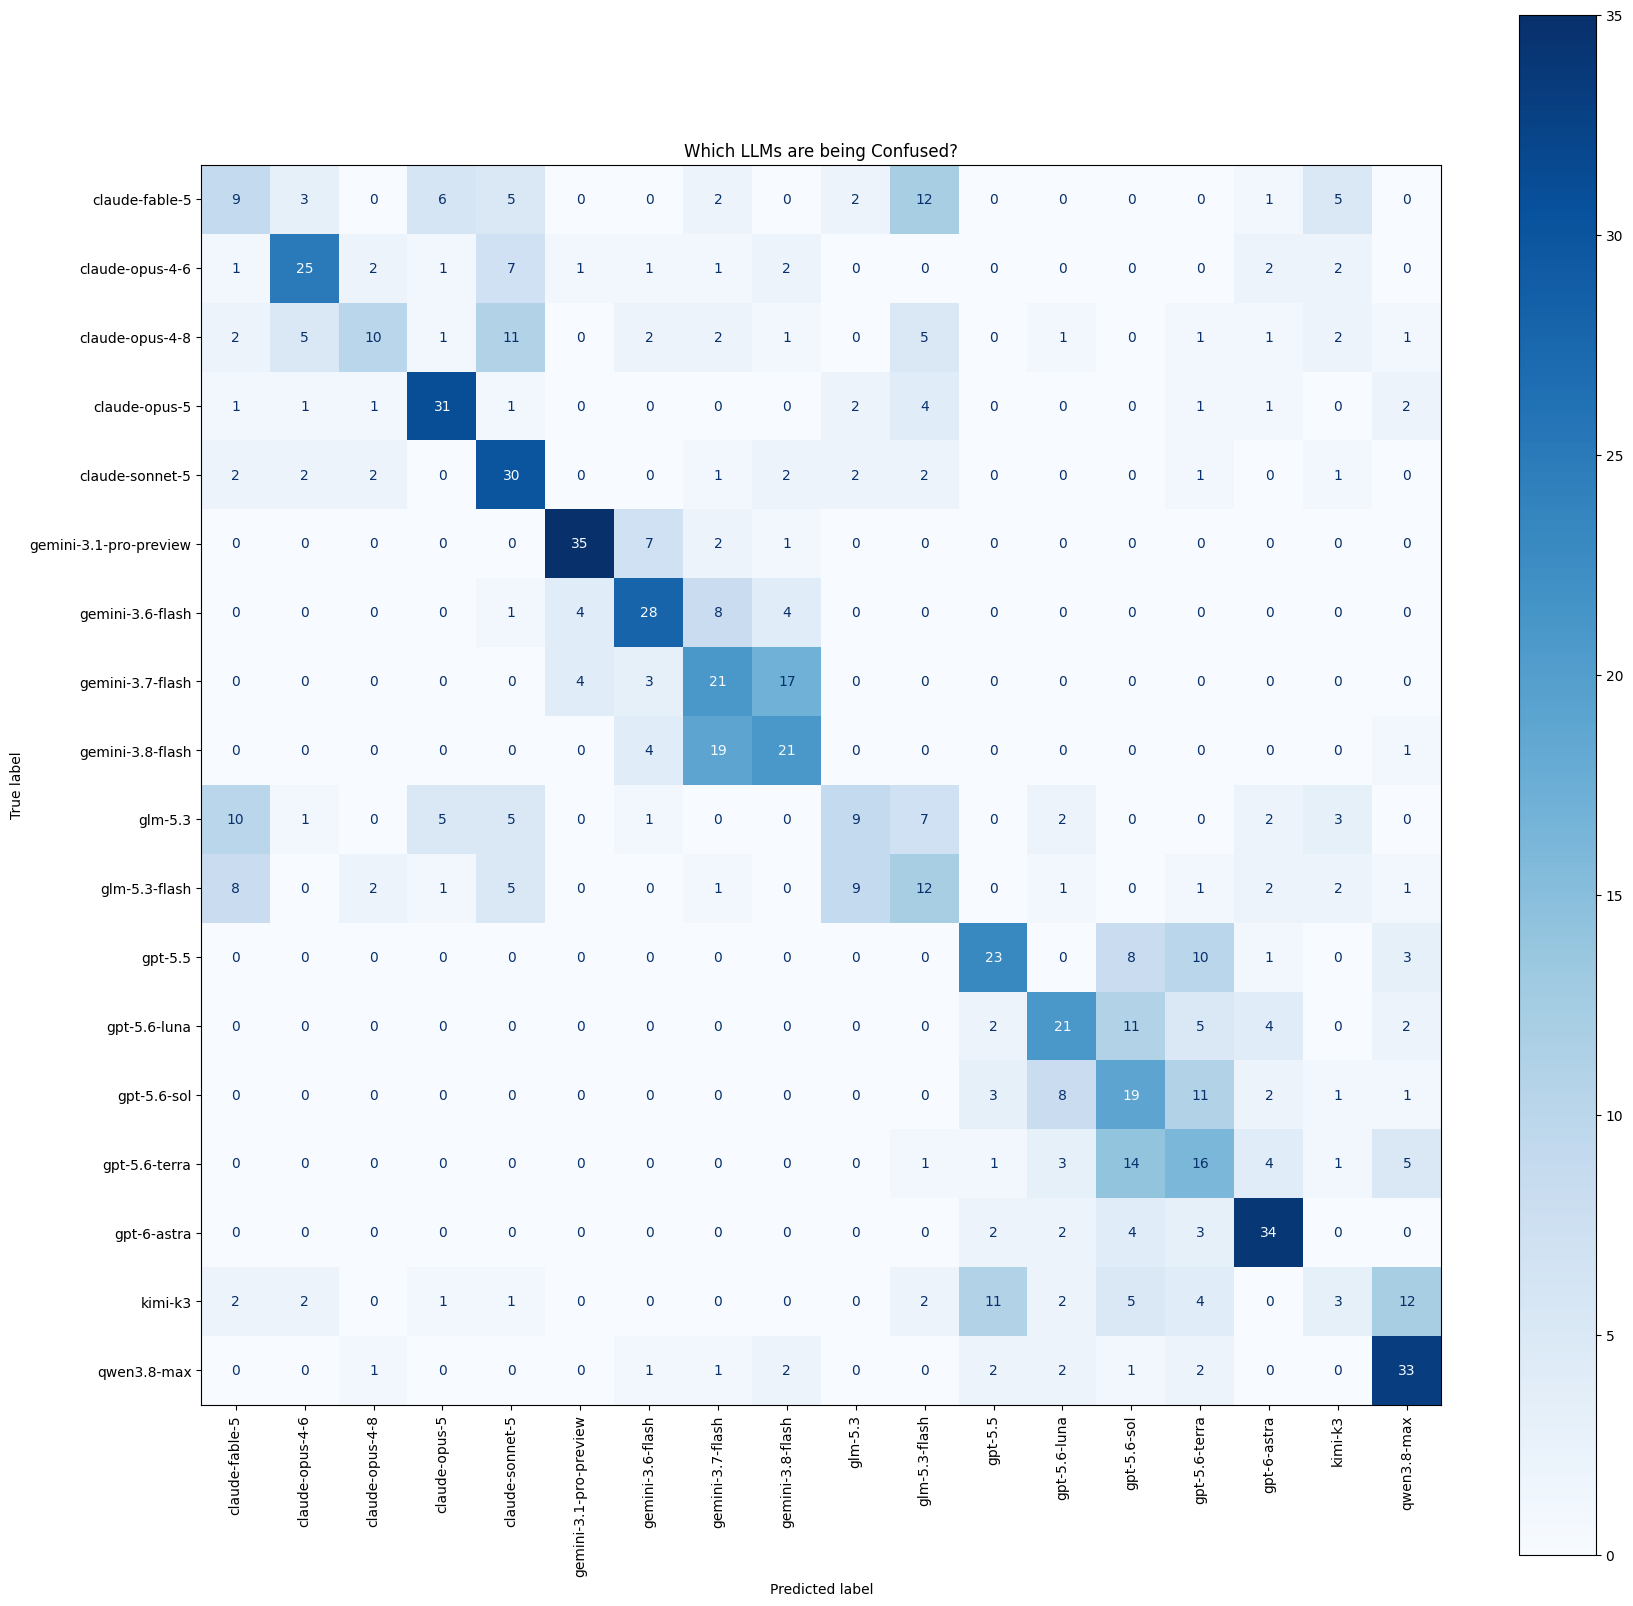

[  733.2s] ✓ Saved submission.parquet


In [7]:
import glob, os, re, time, warnings, pathlib
import numpy as np, pandas as pd
from scipy.sparse import hstack, vstack
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import GroupShuffleSplit
from sklearn.multiclass import OneVsRestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import RobustScaler
from sklearn.svm import LinearSVC
import matplotlib.pyplot as plt
import torch
from transformers import AutoModel, AutoTokenizer

warnings.filterwarnings("ignore")
T0 = time.time()
def log(*a): print(f"[{time.time() - T0:7.1f}s]", *a, flush=True)
def ba(t, s): return balanced_accuracy_score(t, np.asarray(s).argmax(1))

# ============================================================================
# 1. DATA & SPLIT (Same as V45)
# ============================================================================
def find_data_dir():
    for pat in ("/kaggle/input/**/train.csv", "/kaggle/input/*/train.csv"):
        for h in sorted({os.path.dirname(p) for p in glob.glob(pat, recursive=True)}):
            if os.path.exists(os.path.join(h, "test.csv")):
                return pathlib.Path(h)
    raise FileNotFoundError("train.csv not found")

DATA_DIR = find_data_dir()
train_full = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
for df in (train_full, test_df): df["text"] = df["text"].fillna("").astype(str)

CLASSES = np.array(sorted(train_full["model"].unique()))
NC = len(CLASSES)

MIN_W, MAX_W, MIN_CHARS = 35, 280, 200
def clean_external(df):
    df = df[["text", "model"]].dropna(subset=["model"])
    df = df[df["model"].isin(CLASSES)].copy()
    df["text"] = df["text"].fillna("").astype(str)
    nw = df["text"].str.split().str.len()
    return df[nw.between(MIN_W, MAX_W) & (df["text"].str.len() > MIN_CHARS)]

def load_external():
    out = []
    for p in glob.glob("/kaggle/input/**/passages.csv", recursive=True):
        if "/name-that-llm/" in p: continue
        try:
            d = pd.read_csv(p)
            if "passes_funnel" in d.columns: d = d[d["passes_funnel"].astype(bool)]
            if "is_refusal" in d.columns: d = d[~d["is_refusal"].astype(bool)]
            if {"text", "model"} <= set(d.columns): out.append(clean_external(d))
        except: pass
    return pd.concat(out, ignore_index=True).drop_duplicates(subset=["text"]) if out else pd.DataFrame(columns=["text", "model"])

EXT = load_external()
if len(EXT):
    E_X = EXT["text"].values
    E_Y = np.searchsorted(CLASSES, EXT["model"].values)
    log(f"✅ External data: {len(E_X)} rows")
else:
    E_X, E_Y = np.array([]), np.array([])

gss = GroupShuffleSplit(n_splits=1, train_size=0.7, random_state=42)
tr_idx, va_idx = next(gss.split(train_full, groups=train_full["prompt_id"]))
train_df = train_full.iloc[tr_idx].reset_index(drop=True)
val_df = train_full.iloc[va_idx].reset_index(drop=True)

y_train = np.searchsorted(CLASSES, train_df["model"].values)
y_val = np.searchsorted(CLASSES, val_df["model"].values)
X_train, X_val = train_df["text"].values, val_df["text"].values
XT = test_df["text"].values

# ============================================================================
# 2. MULTI-DEPTH EMBEDDINGS
# ============================================================================
def find_model():
    cfgs = glob.glob("/kaggle/input/**/config.json", recursive=True)
    cands = [os.path.dirname(c) for c in cfgs if "deberta" in c.lower() and "small" not in c.lower()]
    return cands[0] if cands else None

MODEL_PATH = find_model()
LLM_E_train = LLM_E_val = LLM_E_test = LLM_E_ext = None

if MODEL_PATH:
    log(f"Extracting multi-depth embeddings from {MODEL_PATH}...")
    tok = AutoTokenizer.from_pretrained(MODEL_PATH, use_fast=True)
    model = AutoModel.from_pretrained(MODEL_PATH).eval()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    if device == "cuda": model = model.half()
    
    LAYERS = [12, 18, 24] 

    @torch.inference_mode()
    def embed(texts, batch=16, max_len=384):
        chunks = []
        for i in range(0, len(texts), batch):
            enc = tok(list(texts[i:i + batch]), truncation=True, max_length=max_len, padding=True, return_tensors="pt").to(device)
            if device == "cuda":
                enc = {k: (v.half() if v.dtype == torch.float32 else v) for k, v in enc.items()}
            hs = model(**enc, output_hidden_states=True).hidden_states
            mf = enc["attention_mask"].unsqueeze(-1).float()
            chunks.append(np.hstack([((hs[L].float() * mf).sum(1) / mf.sum(1).clamp(min=1)).cpu().numpy() for L in LAYERS]))
        return np.vstack(chunks).astype(np.float32)

    LLM_E_train = embed(X_train)
    LLM_E_val = embed(X_val)
    LLM_E_test = embed(XT)
    LLM_E_ext = embed(E_X) if len(E_X) else None
    log(f"✓ Embeddings: {LLM_E_train.shape}")
    del model; torch.cuda.empty_cache()

# ============================================================================
# 3. FEATURES & MODELS (Same as V45)
# ============================================================================
def style_feats(texts):
    rows = []
    for t in texts:
        nw, nc = max(len(t.split()), 1), max(len(t), 1)
        alpha = max(sum(c.isalpha() for c in t), 1)
        rows.append([
            np.log1p(nc), np.log1p(nw), nc / nw,
            (t.count("\u2014") + t.count("\u2013")) / nc * 1000,
            t.count(";") / nc * 1000, t.count(",") / nc * 1000,
            len(re.findall(r"\*\*.+?\*\*", t)), len(re.findall(r"^\s*[\*\-\u2022]\s+", t, re.M)),
            sum(c.isupper() for c in t) / alpha, len(re.findall(r"[\u200B-\u200D\uFEFF]", t))
        ])
    return np.nan_to_num(np.array(rows, dtype=np.float64))

S_train = style_feats(X_train)
S_val = style_feats(X_val)
S_test = style_feats(XT)
S_ext = style_feats(E_X) if len(E_X) else np.zeros((0, S_train.shape[1]))

sc_style = RobustScaler().fit(S_train)
S_train_sc = sc_style.transform(S_train)
S_val_sc = sc_style.transform(S_val)
S_test_sc = sc_style.transform(S_test)
S_ext_sc = sc_style.transform(S_ext)

c_vec = TfidfVectorizer(analyzer="char", ngram_range=(1, 5), lowercase=False, sublinear_tf=True, min_df=2, max_features=200000)
w_vec = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), lowercase=False, sublinear_tf=True, min_df=2, max_features=100000)

fit_text = np.concatenate([X_train, E_X]) if len(E_X) else X_train
fit_y = np.concatenate([y_train, E_Y]) if len(E_X) else y_train

A_fit = hstack([c_vec.fit_transform(fit_text), w_vec.fit_transform(fit_text)]).tocsr()
A_val = hstack([c_vec.transform(X_val), w_vec.transform(X_val)]).tocsr()
A_test = hstack([c_vec.transform(XT), w_vec.transform(XT)]).tocsr()

OOF, TEST = {}, {}
log("Training Base Models...")
def align(A, cls):
    A = np.asarray(A)
    if A.shape[1] == NC: return A
    out = np.full((A.shape[0], NC), A.min() - 1.0)
    out[:, cls] = A
    return out

# 1. SVM
svm = LinearSVC(C=0.5, class_weight="balanced", dual=False, max_iter=5000).fit(A_fit, fit_y)
OOF["svm"] = align(svm.decision_function(A_val), svm.classes_)
TEST["svm"] = align(svm.decision_function(A_test), svm.classes_)
log(f"  SVM Val: {ba(y_val, OOF['svm']):.4f}")

# 2. Ridge
ridge = OneVsRestClassifier(RidgeClassifier(alpha=1.0, class_weight="balanced")).fit(A_fit, fit_y)
OOF["ridge"] = align(ridge.decision_function(A_val), ridge.classes_)
TEST["ridge"] = align(ridge.decision_function(A_test), ridge.classes_)
log(f"  Ridge Val: {ba(y_val, OOF['ridge']):.4f}")

# 3. ExtraTrees
svd = TruncatedSVD(n_components=100, random_state=42)
Z_fit = svd.fit_transform(A_fit)
Z_val = svd.transform(A_val)
Z_test = svd.transform(A_test)
X_tree_fit = np.hstack([Z_fit, np.vstack([S_train_sc, S_ext_sc]) if len(E_X) else S_train_sc])
X_tree_val = np.hstack([Z_val, S_val_sc])
X_tree_test = np.hstack([Z_test, S_test_sc])
et = ExtraTreesClassifier(n_estimators=300, max_depth=12, class_weight="balanced", random_state=42, n_jobs=-1).fit(X_tree_fit, fit_y)
OOF["et"] = align(np.log(et.predict_proba(X_tree_val) + 1e-9), et.classes_)
TEST["et"] = align(np.log(et.predict_proba(X_tree_test) + 1e-9), et.classes_)
log(f"  ExtraTrees Val: {ba(y_val, OOF['et']):.4f}")

# 4-5. DeBERTa Models
if LLM_E_train is not None:
    sc_llm = RobustScaler().fit(LLM_E_train)
    Z_tr = sc_llm.transform(LLM_E_train)
    Z_va = sc_llm.transform(LLM_E_val)
    Z_te = sc_llm.transform(LLM_E_test)
    if LLM_E_ext is not None:
        Z_tr = np.vstack([Z_tr, sc_llm.transform(LLM_E_ext)])
        fit_y_emb = np.concatenate([y_train, E_Y])
    else:
        fit_y_emb = y_train

    mlp = MLPClassifier(hidden_layer_sizes=(128, 64), alpha=0.01, max_iter=500, random_state=42, early_stopping=True).fit(Z_tr, fit_y_emb)
    OOF["mlp"] = align(np.log(mlp.predict_proba(Z_va) + 1e-9), np.arange(NC))
    TEST["mlp"] = align(np.log(mlp.predict_proba(Z_te) + 1e-9), np.arange(NC))
    log(f"  MLP Val: {ba(y_val, OOF['mlp']):.4f}")

    lr_emb = LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000).fit(Z_tr, fit_y_emb)
    OOF["lr_emb"] = align(lr_emb.decision_function(Z_va), lr_emb.classes_)
    TEST["lr_emb"] = align(lr_emb.decision_function(Z_te), lr_emb.classes_)
    log(f"  LR (Emb) Val: {ba(y_val, OOF['lr_emb']):.4f}")

# ============================================================================
# 4. EQUAL-WEIGHT BLEND (The 0.4691 Configuration)
# ============================================================================
def rownorm(s):
    s = np.asarray(s, dtype=np.float64)
    return (s - s.mean(1, keepdims=True)) / (s.std(1, keepdims=True) + 1e-9)

names = list(OOF.keys())
pred_val = sum(rownorm(OOF[k]) for k in names) / len(names)
log(f"🏆 Equal-Weight Blend Val: {ba(y_val, pred_val):.4f}")

pred_test = sum(rownorm(TEST[k]) for k in names) / len(names)
pred = CLASSES[pred_test.argmax(1)]

# ============================================================================
# 5. DIAGNOSTIC: CONFUSION MATRIX
# ============================================================================
log("Generating Confusion Matrix...")
val_pred_classes = CLASSES[pred_val.argmax(1)]
true_classes = CLASSES[y_val]

cm = confusion_matrix(true_classes, val_pred_classes, labels=CLASSES)

fig, ax = plt.subplots(figsize=(20, 20))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES)
disp.plot(cmap='Blues', ax=ax, xticks_rotation='vertical', values_format='d')
plt.title('Which LLMs are being Confused?')
plt.show()

# Save Submission
sub = pd.DataFrame({"id": test_df["id"].values, "model": pred})
sub.to_csv("submission.csv", index=False)
sub.to_parquet("submission.parquet", index=False)
log("✓ Saved submission.parquet")